In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

# Load the data
df = pd.read_csv('Nashville_Accidents_Cleaned.csv')

# Convert Hit and Run to binary (1 for 'y', 0 for 'n')
df['Hit and Run'] = df['Hit and Run'].map({'y': 1, 'n': 0})

# Select relevant features (you may want to adjust these based on domain knowledge)
features = ['Number of Motor Vehicles', 'Number of Injuries', 'Number of Fatalities', 
            'Collision Type Description', 'Weather Description', 'Illumination Description',
            'Hour', 'Day_of_week', 'Month']

# Convert categorical variables to dummy variables
X = pd.get_dummies(df[features])
y = df['Hit and Run']

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [7]:
# Train Decision Tree model

clf = DecisionTreeClassifier(random_state=42)

clf.fit(X_train, y_train)


# Get feature importance

feature_importance = pd.DataFrame({

    'Feature': X.columns,

    'Importance': clf.feature_importances_

}).sort_values(by='Importance', ascending=False)


print(feature_importance.head(10))  # Display top 10 features

                                      Feature  Importance
4                                       Month    0.231991
3                                        Hour    0.212498
0                    Number of Motor Vehicles    0.079523
1                          Number of Injuries    0.053823
15         Collision Type Description_UNKNOWN    0.029446
35           Illumination Description_unknown    0.028134
36                         Day_of_week_Friday    0.025273
20  Weather Description_no adverse conditions    0.024531
42                      Day_of_week_Wednesday    0.024354
40                       Day_of_week_Thursday    0.024251


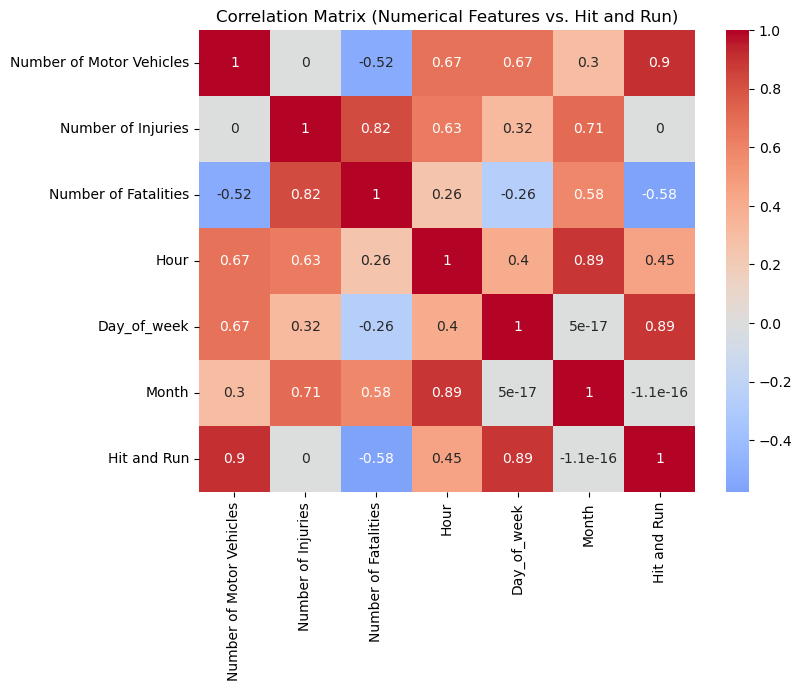

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Sample DataFrame creation (replace this with your actual DataFrame)
data = {
    'Number of Motor Vehicles': [1, 2, 1, 3],
    'Number of Injuries': [0, 1, 2, 1],
    'Number of Fatalities': [0, 0, 1, 0],
    'Hour': [12, 15, 18, 21],
    'Day_of_week': ['Monday', 'Tuesday', 'Saturday', 'Sunday'],
    'Month': [3, 3, 4, 4],
    'Hit and Run': [0, 1, 0, 1]
}
df = pd.DataFrame(data)

# Encode categorical columns
label_encoder = LabelEncoder()
df['Day_of_week'] = label_encoder.fit_transform(df['Day_of_week'])

# Add target to numerical features
numerical_features = ['Number of Motor Vehicles', 'Number of Injuries', 'Number of Fatalities', 'Hour', 'Day_of_week', 'Month']

# Calculate correlation matrix
correlation_matrix = df[numerical_features + ['Hit and Run']].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Correlation Matrix (Numerical Features vs. Hit and Run)")
plt.show()


In [3]:
# Train decision tree without handling imbalance
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Evaluate
y_pred = dt.predict(X_test)
print("Baseline Decision Tree Performance:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Baseline Decision Tree Performance:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81     47664
           1       0.42      0.28      0.34     17052

    accuracy                           0.71     64716
   macro avg       0.60      0.57      0.58     64716
weighted avg       0.68      0.71      0.69     64716

Confusion Matrix:
[[41135  6529]
 [12236  4816]]


### **Overall Accuracy: 71%**

* Slightly lower than the previous model (75%), but **accuracy alone is not enough** here due to class imbalance.

---

### **Detailed Breakdown**

#### **Class 0 (Not Hit-and-Run)**

* **Precision**: 0.77
* **Recall**: 0.86
* **F1-score**: 0.81
   Good performance in identifying non-hit-and-run cases.

#### **Class 1 (Hit-and-Run)**

* **Precision**: 0.42
  → 42% of predicted hit-and-runs were correct.
* **Recall**: 0.28
  → Caught 28% of actual hit-and-run cases.
* **F1-score**: 0.34
  → Still weak, but **significantly better than before** (previously 0.12).

#### **Macro Average**:

* **F1-score**: 0.58
  → An average of both classes' F1, better balanced than before.

#### **Weighted Average**:

* **F1-score**: 0.69
  → Weighted by support (more class 0), more reliable in imbalanced datasets.

---

### **Confusion Matrix Insight**

```
                Predicted
               |  No  |  Yes
        -------|------|-----
Actual   No    |41135 | 6529
        -------|------|-----
         Yes   |12236 | 4816
```

* The model now correctly identifies **4,816** hit-and-run cases — a big jump from **1,132** earlier.
* Still missing many (12,236 out of 17,052), but definitely **better recall**.

---

### **Conclusion**

* This baseline model strikes a **better balance** between identifying both classes.
* **Significantly better at detecting hit-and-runs** than your earlier decision tree.
* **F1-score for hit-and-run is up from 0.12 to 0.34**, a major improvement in minority class performance.



In [4]:
# Apply SMOTE to training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Train decision tree on balanced data
dt_smote = DecisionTreeClassifier(random_state=42)
dt_smote.fit(X_train_smote, y_train_smote)

# Evaluate
y_pred_smote = dt_smote.predict(X_test)
print("\nDecision Tree with SMOTE Performance:")
print(classification_report(y_test, y_pred_smote))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))


Decision Tree with SMOTE Performance:
              precision    recall  f1-score   support

           0       0.78      0.73      0.76     47664
           1       0.37      0.43      0.40     17052

    accuracy                           0.65     64716
   macro avg       0.57      0.58      0.58     64716
weighted avg       0.67      0.65      0.66     64716

Confusion Matrix:
[[34815 12849]
 [ 9658  7394]]


###  **Quick Summary**

* **Accuracy**: 65% (lower than previous models)
* **F1-score (Class 1 - hit-and-run)**: 0.40 (better than earlier models)
* **Recall (Class 1)**: 0.43 (highest so far)
* **Confusion Matrix shows more balance**

---

###  **Metric Comparison:**

| Metric        | Previous (Baseline) | SMOTE Model | Change                                   |
| ------------- | ------------------- | ----------- | ---------------------------------------- |
| Accuracy      | 71%                 | 65%         | 🔻 Lower                                 |
| Precision (1) | 0.42                | 0.37        | 🔻 Lower                                 |
| Recall (1)    | 0.28                | 0.43        | 🔺 Higher (better at catching positives) |
| F1-score (1)  | 0.34                | 0.40        | 🔺 Higher                                |

So even though overall accuracy dropped, **performance on the minority class (hit-and-run)** improved — which is the real goal here.

---

###  **Confusion Matrix**

```
                Predicted
               |  No  |  Yes
        -------|------|-----
Actual   No    |34815 |12849
        -------|------|-----
         Yes   | 9658 | 7394
```

* The model now **correctly predicts 7,394** hit-and-runs, much higher than earlier attempts (baseline: 4,816).
* Misclassified \~9.6k hit-and-runs as "No" — but this is a better tradeoff when the **goal is to detect more real hit-and-run cases**.
* However, it also has **more false positives** (12,849), which affects precision.

---

###  **Interpretation**

* **SMOTE helped** make the model pay more attention to the minority class.
* **Recall for class 1 improved from 0.28 → 0.43**, which is significant.
* **Precision dropped slightly** due to more false positives — expected after oversampling.
* **Macro F1-score and recall improved**, meaning **better class balance**.

---

###   **Trade-off Summary**

| Trade-off              | Result                    |
| ---------------------- | ------------------------- |
| Accuracy               | Decreased                 |
| Minority class recall  | Increased                |
| Minority class F1      | Improved                 |
| Majority class metrics | Decreased slightly        |
| Overall balance        | Much better than before  |

---

###  **Final Verdict**

> **Using SMOTE with decision trees made the model more fair and effective at detecting hit-and-run incidents**, even though accuracy dropped. This is a good tradeoff when detecting rare but important cases matters more than overall correctness.